In [1]:
import torch
import torchvision
from torchvision import datasets , transforms
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import torch.nn as nn

In [7]:
format_transform=transforms.Compose([
    transforms.Resize((28,28)),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor()
])

In [10]:
train_data=datasets.MNIST(
    download=True,
    train=True,
    target_transform=None,
    root=r'/root',
    transform=format_transform

)

test_data=datasets.MNIST(
    download=True,
    train=False,
    target_transform=None,
    root=r'/data',
    transform=ToTensor()

)

In [11]:
len(train_data)  , len(test_data)

(60000, 10000)

In [36]:
train_loader=DataLoader(dataset=train_data,shuffle=True,batch_size=128,pin_memory=True,num_workers=2)
test_loader=DataLoader(dataset=test_data,shuffle=False,batch_size=256,num_workers=2)

In [37]:
len(train_loader)  ,len(test_loader)

(469, 40)

In [38]:
import matplotlib.pyplot as plt

In [40]:
train_data.class_to_idx

{'0 - zero': 0,
 '1 - one': 1,
 '2 - two': 2,
 '3 - three': 3,
 '4 - four': 4,
 '5 - five': 5,
 '6 - six': 6,
 '7 - seven': 7,
 '8 - eight': 8,
 '9 - nine': 9}

In [41]:
# now data is ready time to build a model on it

In [42]:
class spideynetmnist(nn.Module):
  def __init__(self):
    super().__init__()

    self.convlayers=nn.Sequential(
        nn.Conv2d(1,32,3,padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        nn.Conv2d(32,64,3,padding=1,stride=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),


        nn.Conv2d(64,128,3,padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),

        nn.Conv2d(128,256,3,padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),


    )

    self.clf=nn.Sequential(
        nn.AdaptiveAvgPool2d((1,1)),
        nn.Flatten(),
        nn.Linear(256,1024),
        nn.Dropout(p=0.2),
        nn.ReLU(),
        nn.Linear(1024,10)
    )

  def forward(self,x):
    return self.clf(self.convlayers(x))

In [43]:
device=torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

In [44]:
device

device(type='cuda')

In [45]:
model1=spideynetmnist().to(device)

In [46]:
model1


spideynetmnist(
  (convlayers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU()
  )
  (clf): Seq

In [56]:
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(lr=0.001,params=model1.parameters() , weight_decay=0.00001)

In [57]:
def train_loop(epoch
               ,model:torch.nn.Module,
               loss_fucntion:torch.nn.Module,
               optimizer:torch.nn.Module,
               dataloader:torch.utils.data.DataLoader,
               device:torch.device=device):
  model.train()
  train_loss=0
  for batch,(X,y) in enumerate(train_loader):
    X,y=X.to(device),y.to(device)
    y_pred=model(X)
    y_pred=y_pred.to(device)
    loss=loss_function(y_pred,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_loss+=loss.item()
  train_loss/=len(dataloader)
  train_loss=torch.tensor(train_loss)

  if epoch %1==0:
    print(f'epoch -> {epoch} train loss -> {train_loss.item()}')

In [58]:
def test_loop(epoch,
              model:torch.nn.Module,
              loss_fucntion:torch.nn.Module,
              optimizer:torch.nn.Module,
              dataloader:torch.utils.data.DataLoader,
              device:torch.device=device):
  model.eval()
  test_loss = 0
  with torch.inference_mode():
    for X,y in dataloader:
      X,y=X.to(device),y.to(device)
      y_pred=model(X)
      loss=loss_function(y_pred,y)
      test_loss+=loss.item()
    test_loss/=len(dataloader)
    test_loss=torch.tensor(test_loss)

    if epoch % 1 ==0:
      print(f'test_loss -> {test_loss.item()}')

In [59]:
import tqdm.auto as tqdm

In [60]:
epoch=20

for epoch in tqdm.tqdm(range(epoch)):
  train_loop(epoch,device=device,model=model1,dataloader=train_loader,loss_fucntion=loss_function,optimizer=optimizer)
  test_loop(epoch=epoch,device=device,model=model1,dataloader=test_loader,loss_fucntion=loss_function,optimizer=optimizer)

  0%|          | 0/20 [00:00<?, ?it/s]

epoch -> 0 train loss -> 0.050035446882247925
test_loss -> 0.06279552727937698
epoch -> 1 train loss -> 0.042148929089307785
test_loss -> 0.03206685557961464
epoch -> 2 train loss -> 0.033930592238903046
test_loss -> 0.04887958616018295
epoch -> 3 train loss -> 0.028655726462602615
test_loss -> 0.028882576152682304
epoch -> 4 train loss -> 0.028139734640717506
test_loss -> 0.02479822188615799
epoch -> 5 train loss -> 0.026448432356119156
test_loss -> 0.016784852370619774
epoch -> 6 train loss -> 0.023828906938433647
test_loss -> 0.029335886240005493
epoch -> 7 train loss -> 0.022270292043685913
test_loss -> 0.02402891032397747
epoch -> 8 train loss -> 0.01956143043935299
test_loss -> 0.02760278806090355
epoch -> 9 train loss -> 0.021113624796271324
test_loss -> 0.018198268488049507
epoch -> 10 train loss -> 0.018653975799679756
test_loss -> 0.033608339726924896
epoch -> 11 train loss -> 0.01776716858148575
test_loss -> 0.017444882541894913
epoch -> 12 train loss -> 0.01596936397254467


In [61]:
model1.eval()
correct = 0
total = 0

with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        outputs = model1(X)
        _, predicted = torch.max(outputs.data, 1)
        total += y.size(0)
        correct += (predicted == y).sum().item()

accuracy = 100 * correct / total
print(f'Overall Accuracy of the model on the 10,000 test images: {accuracy:.2f}%')

Overall Accuracy of the model on the 10,000 test images: 99.29%


tensor(2)


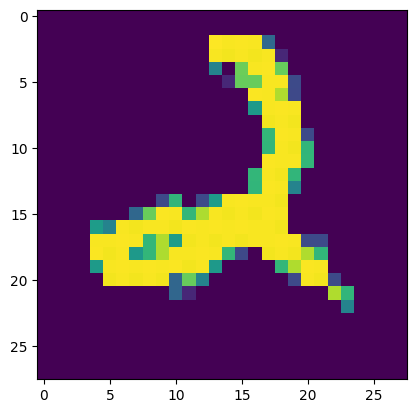

In [77]:
images,labels=next(iter(train_loader))
X=images[12]
plt.imshow(X.permute(1,2,0))
print(labels[12])

In [79]:
X.shape


torch.Size([1, 1, 28, 28])

In [78]:
model1.eval()
with torch.inference_mode():
  X=X.unsqueeze(dim=0)
  X=X.to(device)
  pred=model1(X)
  ans=pred.argmax(dim=1)
  print(ans)

tensor([2], device='cuda:0')


In [80]:
# now time to plot the confussion matrix

In [81]:
from sklearn.metrics import confusion_matrix

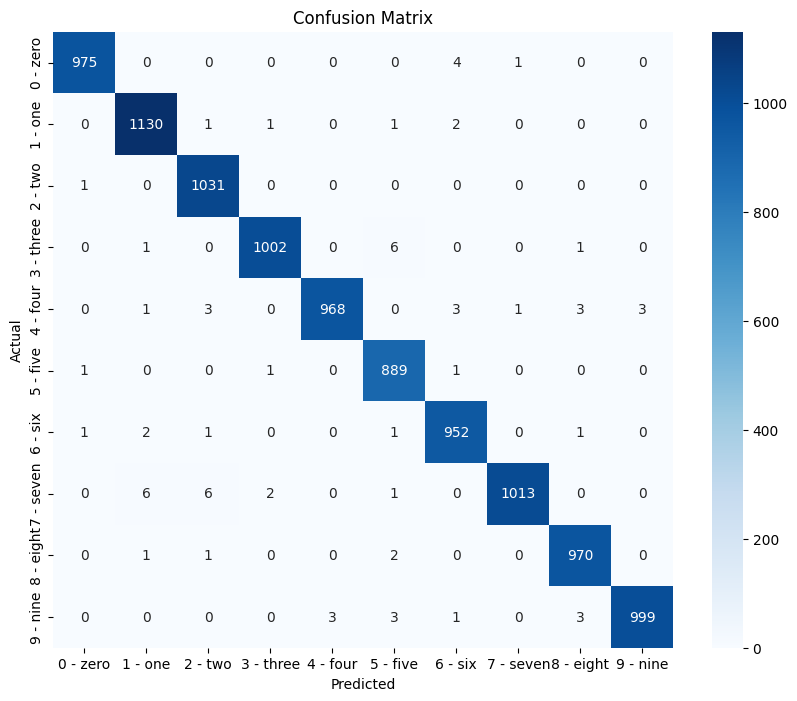

In [84]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

model1.eval()
y_pred = []
y_actual = []

with torch.inference_mode():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        outputs = model1(X)
        preds = outputs.argmax(dim=1)

        y_pred.extend(preds.cpu().numpy())
        y_actual.extend(y.cpu().numpy())

# Calculate confusion matrix
cm = confusion_matrix(y_actual, y_pred)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=train_data.classes, yticklabels=train_data.classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [85]:
model1.eval()
y_pred=[]
y_actual=[]
with torch.inference_mode():
  for X,y in train_loader:
    X,y=X.to(device),y.to(device)
    pred=model1(X)
    pred=pred.argmax(dim=1)
    y_pred.append(pred)
    y_actual.append(y)

In [86]:
len(y_pred)

469

In [87]:
len(y_actual)

469

In [92]:
print(y_actual)

[tensor([8, 7, 3, 9, 0, 8, 8, 5, 3, 0, 4, 1, 1, 3, 0, 3, 0, 2, 1, 3, 5, 3, 3, 9,
        0, 2, 5, 4, 2, 4, 8, 1, 2, 6, 0, 5, 2, 2, 5, 3, 8, 1, 3, 7, 1, 4, 9, 9,
        1, 0, 6, 1, 4, 2, 6, 2, 9, 9, 2, 9, 1, 5, 9, 5, 6, 3, 1, 7, 4, 3, 3, 9,
        1, 4, 2, 1, 4, 0, 5, 1, 1, 6, 6, 4, 3, 4, 2, 0, 3, 1, 8, 7, 1, 5, 4, 4,
        6, 6, 9, 7, 9, 8, 8, 3, 4, 5, 9, 6, 6, 9, 2, 8, 3, 4, 4, 6, 7, 2, 6, 8,
        9, 4, 7, 8, 7, 3, 9, 4], device='cuda:0'), tensor([6, 2, 1, 9, 1, 3, 0, 0, 8, 5, 9, 6, 1, 3, 2, 2, 7, 7, 5, 6, 4, 5, 2, 4,
        9, 9, 5, 4, 0, 8, 5, 3, 1, 2, 8, 7, 4, 4, 6, 6, 6, 0, 1, 3, 0, 5, 0, 9,
        5, 2, 2, 6, 5, 6, 1, 0, 0, 4, 8, 5, 2, 5, 4, 1, 3, 3, 3, 1, 2, 0, 7, 7,
        6, 0, 4, 2, 9, 7, 3, 4, 6, 5, 0, 4, 7, 1, 5, 4, 1, 7, 9, 6, 0, 1, 7, 9,
        6, 6, 4, 0, 6, 5, 1, 9, 9, 8, 9, 1, 1, 6, 1, 9, 0, 7, 2, 0, 3, 1, 5, 8,
        1, 7, 0, 6, 8, 0, 6, 6], device='cuda:0'), tensor([0, 6, 7, 6, 3, 6, 3, 3, 8, 5, 0, 6, 1, 9, 9, 2, 9, 8, 6, 8, 7, 8, 8, 1,
        1, 8, 0, 

In [93]:
# Concatenate the list of batched tensors into single flat tensors
y_pred_flat = torch.cat(y_pred).cpu().numpy()
y_actual_flat = torch.cat(y_actual).cpu().numpy()

# Calculate confusion matrix on the training data
cm_train = confusion_matrix(y_actual_flat, y_pred_flat)
print(cm_train)

[[5911    1    0    0    0    1    8    0    2    0]
 [   0 6721    9    1    0    6    4    1    0    0]
 [   0    4 5948    0    0    0    0    3    2    1]
 [   0    0    1 6110    0   16    0    1    0    3]
 [   3   12   22    0 5720    4   38    2   25   16]
 [   0    0    0    1    0 5416    3    0    1    0]
 [   0    0    1    0    0    4 5912    0    1    0]
 [   0   18    8    2    0    1    0 6226    2    8]
 [   1    1    5    0    0   15    7    0 5821    1]
 [   7    1    0    0    5   11    4    0    9 5912]]


In [94]:
# focous on 5 ,9 and 7 , done this work ~ spidey